# Reto básico 4: interpretación de los segmentos

Se describen los clústeres del reto 3 en lenguaje de negocio: un perfil de cliente y un nombre por segmento que
marketing pueda usar. Se añade el segmento **Flota / Profesional**, que se apartó en el reto 2.

**Entradas:** `clientes_modelo.csv` (features legibles, reto 2) y `segmentos_kmeans.csv` (reto 3).
**Salidas:** `data/processed/clientes_segmentados.csv` y `data/processed/nombres_segmentos.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Especificaciones_proyecto.md").exists())
PROC = ROOT / "data" / "processed"
FIG = ROOT / "modelo" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE = CAT[0]
DIV = ["#e34948", "#f0efec", "#2a78d6"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def show_md(text):
    display(Markdown(text))

In [2]:
cm = pd.read_csv(PROC / "clientes_modelo.csv", dtype={"client_id": str}).set_index("client_id")
lab = pd.read_csv(PROC / "segmentos_kmeans.csv", dtype={"client_id": str}).set_index("client_id").cluster
cm["cluster"] = lab.reindex(cm.index)
cm.loc[cm.grupo == "flota_profesional", "cluster"] = -1
cm["cluster"] = cm.cluster.astype(int)
K = int(lab.nunique())

## 0. Nombres de los segmentos

Los nombres se han puesto tras leer los perfiles de las secciones 1–3. Están fijados por número de clúster: el modelo
del reto 3 usa una semilla fija, así que la numeración es reproducible.

In [3]:
NOMBRES = {
    0: "Ex-cliente por recuperar",
    1: "Berlina clásica al contado",
    2: "Compacto al contado",
    3: "Urbano financiado",
    4: "Trabajador profesional que utiliza furgoneta",
    5: "Familia SUV híbrida",
    6: "Entusiasta AMG",
    7: "Élite eléctrica y lujo",
    -1: "Flota / Profesional",
}
assert set(NOMBRES) - {-1} == set(range(K)), "Los nombres no corresponden a los clústeres del reto 3"

cm["segmento"] = cm.cluster.map(NOMBRES)
pd.DataFrame({"cluster": list(NOMBRES), "nombre": list(NOMBRES.values())}).to_csv(PROC / "nombres_segmentos.csv", index=False)
cm[["cluster", "segmento"]].to_csv(PROC / "clientes_segmentados.csv")
orden = [NOMBRES[c] for c in [*range(K), -1]]

## 1. Tamaño de los segmentos

,clientes,%
segmento,,
Ex-cliente por recuperar,13913,8.021
Berlina clásica al contado,31910,18.397
Compacto al contado,35039,20.201
Urbano financiado,21574,12.438
Trabajador profesional que utiliza furgoneta,16992,9.796
Familia SUV híbrida,27633,15.931
Entusiasta AMG,18287,10.543
Élite eléctrica y lujo,7275,4.194
Flota / Profesional,833,0.480


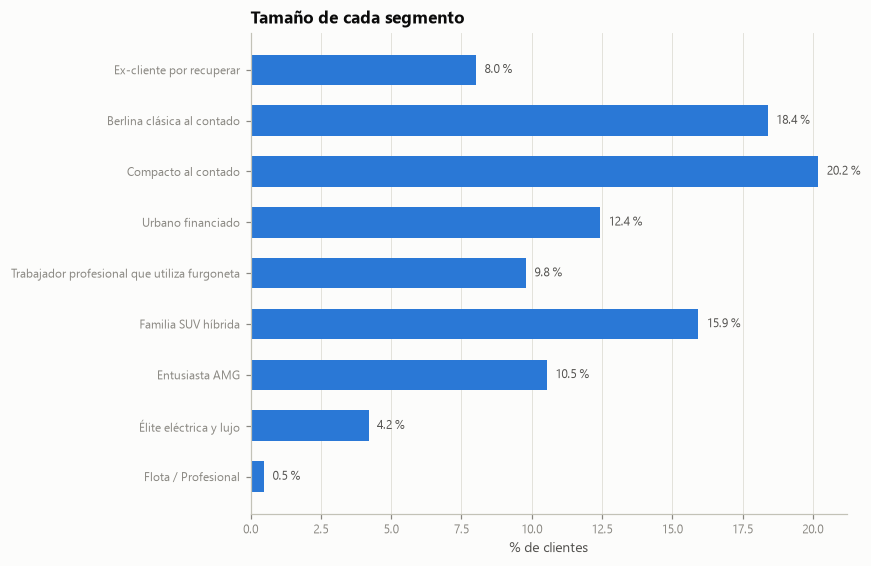

In [4]:
tam = cm.segmento.value_counts().reindex(orden).rename("clientes").to_frame()
tam["%"] = tam.clientes / tam.clientes.sum() * 100
display(tam)
fig, ax = plt.subplots(figsize=(8, 0.45 * len(tam) + 1.2))
s = tam["%"][::-1]
ax.barh(s.index, s.values, height=0.6, color=BLUE)
for i, v in enumerate(s.values):
    ax.text(v + 0.3, i, f"{v:.1f} %", va="center", fontsize=8, color=INK2)
ax.set_xlabel("% de clientes"); ax.grid(axis="y", visible=False)
ax.set_title("Tamaño de cada segmento")
save(fig, "r4_tamano_segmentos.png")

## 2. Perfil numérico por segmento

Medias por segmento de las variables de negocio (sin escalar). La última fila es la media de toda la base.

In [5]:
num = {
    "edad (0=<25 … 5=65+)": "edad_ord", "% Suiza": "es_suiza", "meses como cliente": "meses_cliente",
    "vehículos actuales": "n_vehiculos_actuales", "% leasing activo": "leasing_activo", "% leasing pasado": "leasing_pasado",
    "PA relativo al país (z)": "pa_relativo_pais", "PA/hab (€)": "purchasing_power_per_inhabitant_eur",
    "% compacto": "share_compacto", "% medio": "share_medio", "% SUV": "share_suv", "% lujo/deportivo": "share_lujo_deportivo",
    "% furgoneta": "share_furgoneta", "% AMG": "share_amg", "% electrificado": "share_electrificado", "% BEV": "share_bev",
    "% diésel": "share_diesel", "edad vehículo (años)": "edad_vehiculo", "visitas/vehículo": "visitas_por_vehiculo",
    "% con telemetría": "tiene_telemetria", "km/trayecto": "km_por_trayecto", "horas uso": "horas_uso",
    "relaciones": "n_relaciones", "% consentimiento teléfono": "consent_phone_communication_channel",
}
pct_cols = [k for k in num if k.startswith("%")]
perfil = cm.groupby("segmento")[list(num.values())].mean().reindex(orden)
perfil.columns = list(num)
perfil.loc["TOTAL"] = cm[list(num.values())].mean().to_numpy()
perfil[pct_cols] = perfil[pct_cols] * 100
perfil.round(2).T

segmento,Ex-cliente por recuperar,Berlina clásica al contado,Compacto al contado,Urbano financiado,Trabajador profesional que utiliza furgoneta,Familia SUV híbrida,Entusiasta AMG,Élite eléctrica y lujo,Flota / Profesional,TOTAL
edad (0=<25 … 5=65+),2.990,3.060,2.970,2.670,3.070,3.220,2.480,3.300,2.350,2.960
% Suiza,64.770,57.600,58.680,77.440,59.530,66.230,91.520,61.590,56.300,66.160
meses como cliente,19.560,37.530,34.340,37.190,29.930,33.330,36.900,33.670,66.280,33.900
vehículos actuales,0.000,1.140,1.040,1.250,1.130,1.040,1.000,1.010,2.900,1.010
% leasing activo,0.000,1.010,0.010,100.000,23.620,41.060,32.650,25.280,40.820,26.180
% leasing pasado,11.950,2.480,2.890,0.000,2.920,1.890,3.620,3.370,30.610,3.260
PA relativo al país (z),-0.040,-0.050,-0.040,-0.060,-0.030,0.120,0.030,0.190,-0.000,-0.000
PA/hab (€),"46,159.900","44,395.190","44,487.300","48,712.730","44,727.590","48,353.760","53,636.260","48,368.130","43,833.250","46,893.740"
% compacto,44.570,2.060,99.110,68.230,0.400,0.540,35.320,0.760,30.140,36.490
% medio,28.020,64.480,0.500,22.870,0.550,4.430,26.960,0.730,17.090,20.770


### Mapa de calor: cuánto se desvía cada segmento de la media (en desviaciones estándar)

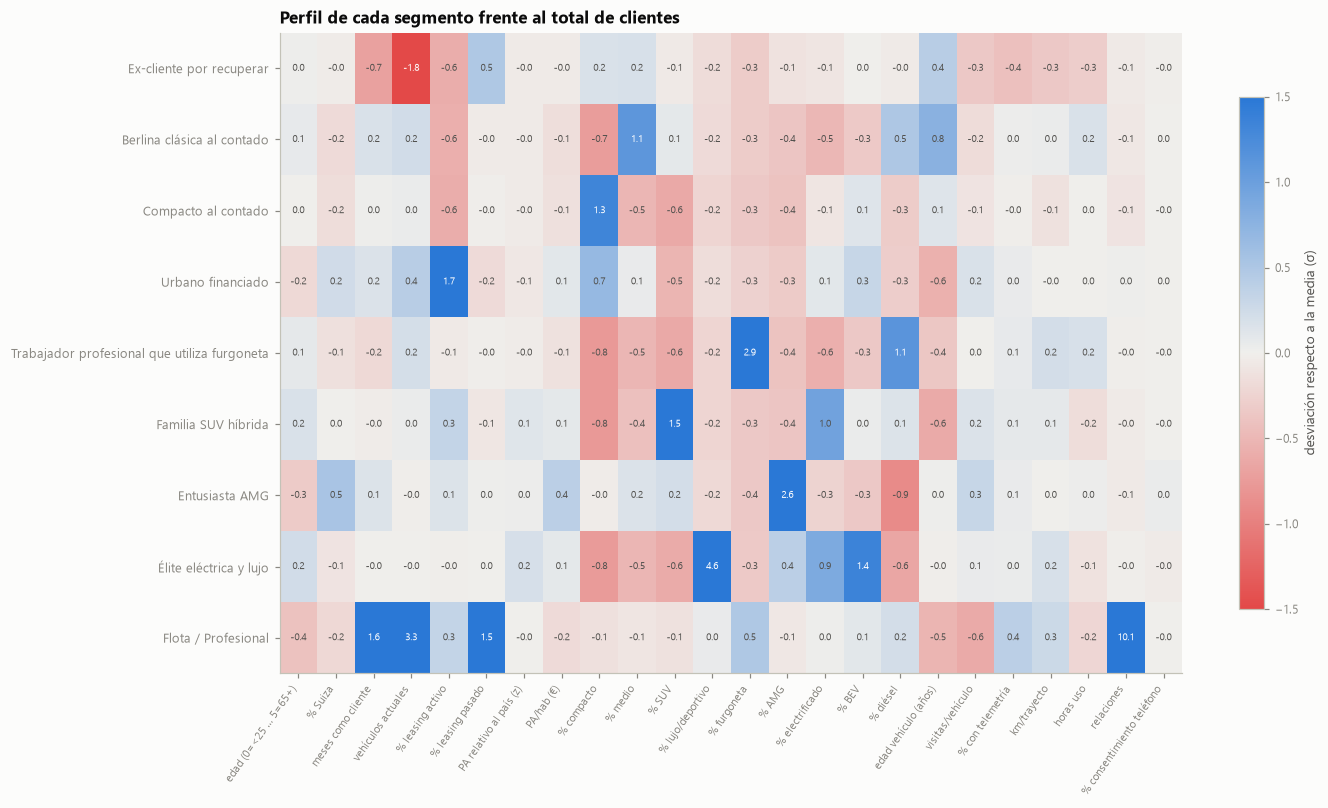

In [6]:
import matplotlib.colors as mcolors
z = (cm.groupby("segmento")[list(num.values())].mean().reindex(orden) - cm[list(num.values())].mean()) / cm[list(num.values())].std()
z.columns = list(num)
fig, ax = plt.subplots(figsize=(13, 0.55 * len(z) + 2.5))
im = ax.imshow(z.values, cmap=mcolors.LinearSegmentedColormap.from_list("div", DIV), vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(z.shape[1])); ax.set_xticklabels(z.columns, rotation=55, ha="right", fontsize=7.5)
ax.set_yticks(range(len(z))); ax.set_yticklabels(z.index, fontsize=8.5); ax.grid(False)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.values[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(z.values[i, j]) > 1 else INK2)
fig.colorbar(im, ax=ax, shrink=0.8, label="desviación respecto a la media (σ)")
ax.set_title("Perfil de cada segmento frente al total de clientes")
save(fig, "r4_perfil_heatmap.png")

## 3. Perfil categórico

In [7]:
def dist(col, orden_cols=None):
    t = pd.crosstab(cm.segmento, cm[col], normalize="index").reindex(orden) * 100
    if orden_cols:
        t = t[[c for c in orden_cols if c in t.columns]]
    return t.round(1)


show_md("**Rango de edad (% del segmento)**")
display(dist("age_range", ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]))
show_md("**Situación de leasing (% del segmento)**")
display(dist("finance_leasing_status"))
show_md("**Familia de modelo principal: las 3 más frecuentes por segmento**")
top_fam = (cm.groupby("segmento").familia_principal.value_counts(normalize=True).mul(100).round(1)
           .groupby(level=0).head(3).rename("%").reset_index())
display(top_fam.assign(segmento=pd.Categorical(top_fam.segmento, orden)).sort_values(["segmento", "%"], ascending=[True, False])
        .set_index(["segmento", "familia_principal"]))
show_md("**Género derivado (solo descriptivo, no se usó en el modelo)**")
display(dist("gender_derived"))

**Rango de edad (% del segmento)**

age_range,<25,25-34,35-44,45-54,55-64,65+
segmento,,,,,,
Ex-cliente por recuperar,4.900,18.200,17.900,17.700,15.400,26.000
Berlina clásica al contado,5.400,13.900,16.900,20.200,20.400,23.100
Compacto al contado,6.800,18.000,15.700,16.700,17.100,25.700
Urbano financiado,5.200,19.000,21.500,23.100,20.000,11.200
Trabajador profesional que utiliza furgoneta,1.200,9.300,24.900,27.400,20.500,16.700
Familia SUV híbrida,1.800,9.700,19.300,24.100,24.000,21.100
Entusiasta AMG,7.500,24.000,21.100,19.600,16.400,11.400
Élite eléctrica y lujo,3.400,10.200,14.700,21.500,24.700,25.500
Flota / Profesional,2.200,24.000,30.400,26.400,13.900,3.100


**Situación de leasing (% del segmento)**

finance_leasing_status,active_FL_and_CASH,active_FL_only,never_active,was_active
segmento,,,,
Ex-cliente por recuperar,0.000,0.000,88.000,12.000
Berlina clásica al contado,0.200,0.800,96.500,2.500
Compacto al contado,0.000,0.000,97.100,2.900
Urbano financiado,12.700,87.300,0.000,0.000
Trabajador profesional que utiliza furgoneta,2.800,20.800,73.500,2.900
Familia SUV híbrida,1.200,39.900,57.000,1.900
Entusiasta AMG,1.100,31.500,63.700,3.600
Élite eléctrica y lujo,1.600,23.600,71.400,3.400
Flota / Profesional,33.100,7.700,28.600,30.600


**Familia de modelo principal: las 3 más frecuentes por segmento**

%
segmento                                     familia_principal        
Ex-cliente por recuperar                     C                  15.600
                                             GLC                15.500
                                             A                  14.400
Berlina clásica al contado                   C                  34.800
                                             GLC                21.800
                                             E                  21.700
Compacto al contado                          B/GLA/GLB          38.300
                                             A                  32.100
                                             CLA                16.700
Urbano financiado                            B/GLA/GLB          24.500
                                             A                  19.000
                                             EQA/EQB            14.100
Trabajador profesional que utiliza furgoneta Van               100.000
Familia SUV híbrida                          GLC                62.300
                                             GLE/GLS            24.500
                                             EQC                 6.600
Entusiasta AMG                               GLC                18.700
                                             A                  16.300
                                             GLE/GLS            14.800
Élite eléctrica y lujo                       EQE/EQS            50.200
                                             S/Maybach          26.500
                                             Deportivo          20.900
Flota / Profesional                          Van                34.000
                                             GLC                16.800
                                             B/GLA/GLB          11.900

**Género derivado (solo descriptivo, no se usó en el modelo)**

gender_derived,female,male,unknown
segmento,,,
Ex-cliente por recuperar,14.800,59.600,25.600
Berlina clásica al contado,11.500,71.400,17.000
Compacto al contado,28.200,54.000,17.800
Urbano financiado,27.700,61.300,11.000
Trabajador profesional que utiliza furgoneta,10.000,68.400,21.600
Familia SUV híbrida,17.100,67.900,14.900
Entusiasta AMG,14.400,71.400,14.300
Élite eléctrica y lujo,8.700,72.500,18.800
Flota / Profesional,6.100,91.600,2.300


C:\Users\fr4nc1s\AppData\Local\Temp\ipykernel_10244\3203233897.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  d["térmico / MHEV"] = 100 - d.sum(1)
C:\Users\fr4nc1s\AppData\Local\Temp\ipykernel_10244\3203233897.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  d["nunca"] = 100 - d.sum(1)


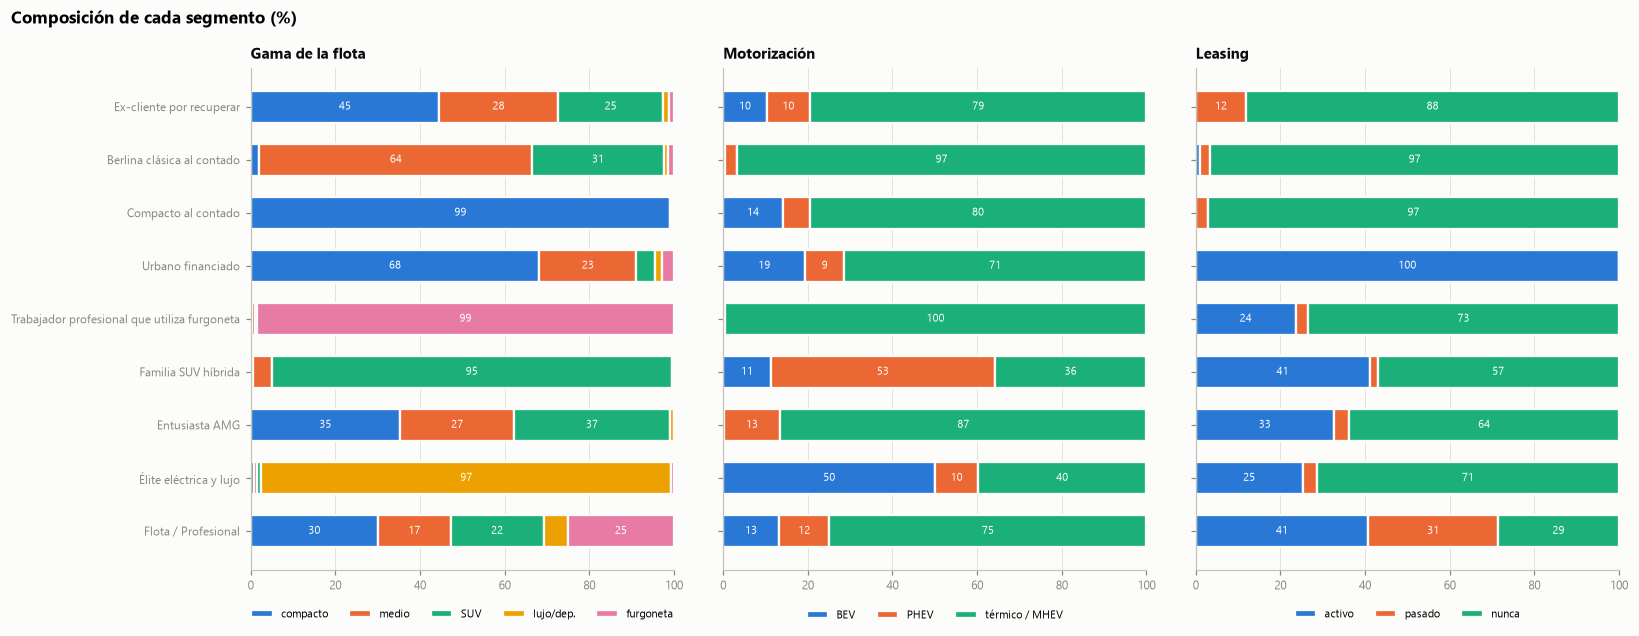

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 0.45 * len(orden) + 1.8), sharey=True)
for ax, (titulo, cols) in zip(axes, [
        ("Gama de la flota", {"compacto": "% compacto", "medio": "% medio", "SUV": "% SUV",
                              "lujo/dep.": "% lujo/deportivo", "furgoneta": "% furgoneta"}),
        ("Motorización", {"BEV": "% BEV", "PHEV+": None, "resto": None}),
        ("Leasing", {"activo": "% leasing activo", "pasado": "% leasing pasado", "nunca": None})]):
    if titulo == "Motorización":
        d = pd.DataFrame({"BEV": perfil["% BEV"], "PHEV": perfil["% electrificado"] - perfil["% BEV"]})
        d["térmico / MHEV"] = 100 - d.sum(1)
    elif titulo == "Leasing":
        d = pd.DataFrame({"activo": perfil["% leasing activo"], "pasado": perfil["% leasing pasado"]})
        d["nunca"] = 100 - d.sum(1)
    else:
        d = pd.DataFrame({k: perfil[v] for k, v in cols.items()})
    d = d.drop(index="TOTAL", errors="ignore")
    left = np.zeros(len(d))
    for i, c in enumerate(d.columns):
        ax.barh(d.index, d[c], left=left, height=0.6, color=CAT[i], edgecolor=SURFACE, linewidth=1.5, label=c)
        for j, v in enumerate(d[c].values):
            if v > 9:
                ax.text(left[j] + v / 2, j, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white")
        left += d[c].values
    ax.set_xlim(0, 100); ax.invert_yaxis() if titulo == "Gama de la flota" else None
    ax.grid(axis="y", visible=False); ax.set_title(titulo, fontsize=10)
    ax.legend(ncol=len(d.columns), loc="upper center", bbox_to_anchor=(0.5, -0.06), fontsize=7)
fig.suptitle("Composición de cada segmento (%)", x=0.01, ha="left", fontsize=11, fontweight="bold")
save(fig, "r4_composicion.png")

## 4. Fichas de segmento para marketing

Las cifras exactas de cada ficha están en la tabla de la sección 2 y en el mapa de calor.

### Ex-cliente por recuperar (~8 %)
**Quién es:** ya no tiene ningún vehículo conectado; su último coche era de media unos 6 años de antigüedad. Es el
segmento con menos meses como cliente, y el 12 % terminó un leasing ("was_active"). Edad y gama como la media: es un
cliente corriente que se ha ido.
**Acción:** campaña de recuperación (*win-back*) con oferta de vehículo de ocasión certificado o un nuevo leasing,
priorizando a los que salieron de un leasing. Canal: email, al que consienten casi todos.
**Nota:** al no existir ya una variable binaria "tiene vehículo actual", los ex-clientes con una flota muy marcada se
quedan en el segmento de su gama (el 9 % de Furgoneta, el 6 % de AMG y el 11 % de Élite no tienen vehículo actual). Para
una campaña de recuperación completa conviene filtrar `n_vehiculos_actuales = 0` en toda la base.

### Berlina clásica al contado (~18 %)
**Quién es:** flota de berlinas medias (C, E) y algo de GLC, prácticamente nunca financiada y con los coches más
antiguos de la base (unos 7 años). Casi no tiene electrificados (3 %).
**Acción:** planes de mantenimiento y de extensión de garantía para vehículos fuera de garantía, y oferta de renovación
con financiación sencilla, con un primer paso a híbrido. Comunicación postal y telefónica, además del email.

### Compacto al contado (~20 %, el mayor)
**Quién es:** flota casi solo de compactos (A, B/GLA/GLB, CLA), sin financiación, con coches de unos 5 años. Un 20 % ya
está electrificado (14 % BEV) y hay una proporción algo mayor de mayores de 65 (26 % frente al 20 %).
**Acción:** renovación hacia un compacto nuevo o EQA/EQB con financiación sencilla y mantenimiento al salir de la
garantía. Comunicación postal y telefónica, además del email.

### Urbano financiado (~12 %)
**Quién es:** el 100 % tiene un leasing activo, coches compactos o medios muy nuevos (unos 3 años), un 19 % de eléctricos
y un perfil algo más joven que la media. Más presente en Suiza (77 %).
**Acción:** renovación anticipada al final del contrato (el momento de máxima receptividad), upgrade a EQ y servicios de
carga y conectividad. Canal digital (app Mercedes me).

### Trabajador profesional que utiliza furgoneta (~10 %)
**Quién es:** su flota es casi exclusivamente furgonetas (V-Class, Vito, Sprinter) y coches bastante nuevos
(unos 4 años). Perfil de 35 a 64 años: autónomos y pequeñas empresas registrados como particulares.
**Acción:** paquetes de servicio con prioridad de taller (minimizar el tiempo inmovilizado), contratos de mantenimiento
por kilometraje y furgonetas eléctricas (eVito, eSprinter), con mensajes de coste total de propiedad.

### Familia SUV híbrida (~16 %)
**Quién es:** su flota es casi solo SUV (GLC, GLE/GLS), con alta presencia de híbridos (el 64 % está electrificado,
sobre todo PHEV), coches de unos 3 años, un 41 % con leasing activo y un perfil de 45 años o más.
**Acción:** paso al siguiente SUV electrificado (EQ SUV / GLC eléctrico), accesorios familiares y de viaje, y planes de
mantenimiento de híbridos.

### Entusiasta AMG (~11 %)
**Quién es:** casi toda su flota es AMG. Es el segmento más joven y el más suizo (92 %), y el que más visitas al taller
hace por vehículo.
**Acción:** eventos de conducción AMG, lanzamientos exclusivos, mantenimiento premium y de altas prestaciones, y
personalización. Comunicación de marca y experiencias más que de precio.

### Élite eléctrica y lujo (~4 %)
**Quién es:** flota de lujo y deportivos (EQE/EQS, Clase S/Maybach, AMG GT) con la mitad en eléctricos. El poder
adquisitivo de su zona es el más alto respecto a su país. Perfil de más edad.
**Acción:** atención personalizada (gestor dedicado), acceso preferente a nuevos EQ y Maybach, y servicios de
conveniencia (recogida y entrega para el taller).

### Flota / Profesional (833 cuentas, fuera del K-Means)
**Quién es:** cuentas con más de 20 relaciones y pocos vehículos actuales: concesionarios, rent-a-car o flotas.
**Acción:** gestión B2B (flotas), no campañas B2C. Además, revisar en el CRM si deben tener rol de particular.

### Uso del vehículo por segmento (solo clientes con telemetría)

La telemetría no se usó para crear los segmentos (reto 2), pero sí sirve para describirlos.

In [9]:
tel = cm[cm.tiene_telemetria == 1].groupby("segmento")[["km_por_trayecto", "horas_uso", "speed_average",
                                                        "fuel_consumption_average"]].median().reindex(orden)
tel.columns = ["km por trayecto (mediana)", "horas de uso (mediana)", "velocidad media (mediana)", "consumo (mediana, l/100 km)"]
tel.round(1)

,km por trayecto (mediana),horas de uso (mediana),velocidad media (mediana),"consumo (mediana, l/100 km)"
segmento,,,,
Ex-cliente por recuperar,14.000,407.200,50.000,7.200
Berlina clásica al contado,14.100,598.800,50.400,7.500
Compacto al contado,13.500,442.000,49.100,6.700
Urbano financiado,13.800,422.700,50.000,7.000
Trabajador profesional que utiliza furgoneta,15.600,514.900,50.000,8.900
Familia SUV híbrida,14.400,349.400,50.000,6.900
Entusiasta AMG,14.000,489.300,49.400,10.400
Élite eléctrica y lujo,17.400,407.200,50.000,4.800
Flota / Profesional,14.400,196.200,47.900,8.200
